In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split,cross_val_predict
from sklearn.metrics import (roc_auc_score,accuracy_score,f1_score,precision_score,recall_score,roc_auc_score,
                             average_precision_score,brier_score_loss,precision_recall_curve,roc_curve)
import warnings
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV

warnings.filterwarnings('ignore')
pd.set_option('display.width',160)
sns.set_theme(style='whitegrid')
RANDOM_STATE=42

RAW=Path('../DATA/heart+disease')




In [2]:
COLS = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach',
        'exang','oldpeak','slope','ca','thal','num']

FILES = {'cleveland'  : 'processed.cleveland.data',
         'hungary'    : 'processed.hungarian.data',
         'switzerland': 'processed.switzerland.data',
         'va'         : 'processed.va.data'}
         

frames=[]

for site,fn in FILES.items():
    d=pd.read_csv(RAW /fn,names=COLS,na_values='?')
    d['site']=site
    frames.append(d)

df=pd.concat(frames,ignore_index=True)
print(df.shape)
df['site'].value_counts()


(920, 15)


site
cleveland      303
hungary        294
va             200
switzerland    123
Name: count, dtype: int64

In [3]:
df.columns
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,site
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,cleveland


In [4]:
#bining based on cardinality
def bining(df,id_threshold=0.95,cat_threshold=5,force_categorical=None,datetime_cols=None):
    n=len(df)
    buckets={'id':[],'datetime':[],'binary':[],'categorical':[],'dis_num':[],'cont':[]}
    datetime_cols=set(datetime_cols or [])
    force_categorical=set(force_categorical or [])

    for col in df.columns:
        s=df[col]
        nunique=s.nunique(dropna=True)

        if pd.api.types.is_datetime64_any_dtype(s) or col in datetime_cols:
            buckets['datetime'].append(col)
            continue
        is_id_like_dtype=pd.api.types.is_integer_dtype(s) or pd.api.types.is_object_dtype(s)
        if n>0 and nunique/n > id_threshold and is_id_like_dtype:
            buckets['id'].append(col)
            continue
        if col in force_categorical:
            buckets['categorical'].append(col)
            continue
        if nunique==2:
            buckets['binary'].append(col)
            continue
        if pd.api.types.is_numeric_dtype(s) and nunique>cat_threshold:
           buckets['cont'].append(col)
        else:
            buckets['categorical'].append(col)
    return buckets

buckets=bining(df)
buckets

{'id': [],
 'datetime': [],
 'binary': ['sex', 'fbs', 'exang'],
 'categorical': ['cp', 'restecg', 'slope', 'ca', 'thal', 'num', 'site'],
 'dis_num': [],
 'cont': ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']}

In [5]:
for c in df[buckets['cont']].columns:
    print(c, (df[c]==0).sum(),(df[c] < 0).sum(),(df[c] > df[c].quantile(.999)*3).sum())

age 0 0 0
trestbps 1 0 0
chol 172 0 0
thalach 0 0 0
oldpeak 370 12 0


In [6]:
for c in ['chol','trestbps']:
    n_zero= (df[c]==0).sum()
    df.loc[df[c]==0,c]=np.nan
    print(f'{c} :{n_zero} zeros to NaN')

df['target']=(df['num']>0).astype(int)
df.drop(columns='num',inplace=True)

print(f'prevalence: {round(df['target'].mean(),3)}')
print(df['target'].value_counts())

chol :172 zeros to NaN
trestbps :1 zeros to NaN
prevalence: 0.553
target
1    509
0    411
Name: count, dtype: int64


In [7]:
def audit(df):
    return pd.DataFrame({
        'nul values':df.isnull().sum(),
        'null _%':df.isnull().mean()*100,
        'unique':df.nunique(),
        'unique_%':((df.nunique()/len(df))*100),
        'dtype':df.dtypes.astype(str),
        'sample':df.loc[0] })
audit(df)


,nul values,null _%,unique,unique_%,dtype,sample
age,0,0.000000,50,5.434783,float64,63.0
sex,0,0.000000,2,0.217391,float64,1.0
cp,0,0.000000,4,0.434783,float64,1.0
trestbps,60,6.521739,60,6.521739,float64,145.0
chol,202,21.956522,216,23.478261,float64,233.0
fbs,90,9.782609,2,0.217391,float64,1.0
restecg,2,0.217391,3,0.326087,float64,2.0
thalach,55,5.978261,119,12.934783,float64,150.0
exang,55,5.978261,2,0.217391,float64,0.0
oldpeak,62,6.739130,53,5.760870,float64,2.3


In [8]:
#MCA MAR or MNAR
miss_by_site=(df.groupby('site').apply(lambda g:g.isna().mean()*100,include_groups=False).round(1))
miss_by_site.loc[:,(miss_by_site.max()>0)]

,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
site,,,,,,,,,,
cleveland,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.3,0.7
hungary,0.3,7.8,2.7,0.3,0.3,0.3,0.0,64.6,99.0,90.5
switzerland,1.6,100.0,61.0,0.8,0.8,0.8,4.9,13.8,95.9,42.3
va,28.5,28.0,3.5,0.0,26.5,26.5,28.0,51.0,99.0,83.0


In [9]:

pd.crosstab(df['site'],df['target'],normalize='index').round(3)


target,0,1
site,,
cleveland,0.541,0.459
hungary,0.639,0.361
switzerland,0.065,0.935
va,0.255,0.745


reading above tables side by side , for 
clv: balance data , full clinical workup,  more general population 
swt: very high prev, most likely only the diseased were included in the trials . and chol is fully missing , ca ~ 95 
va: moderate missing across board, ca heavily missing . prev suggests same case as swt , only less extreme.
hung: slope ca, thal almost missing entirely , but others are relatively complete. prev is lowest. missingness doesnt track prev the way swt does.

key takeaways
missingness and prev vary strongly by site. in case of swz and va they move together
so missingness is not at random,so a column like ca being missing might itself be info about site.
if we build ' is this missing ' indicator then that may just be end up being proxy for site. the model could just learn 'missing> prob singapore > probably diseased' , whihc is not good for generalisation 

so argument for checking performance isnt driven by one or 2 sites, and using stratified train test split by site.



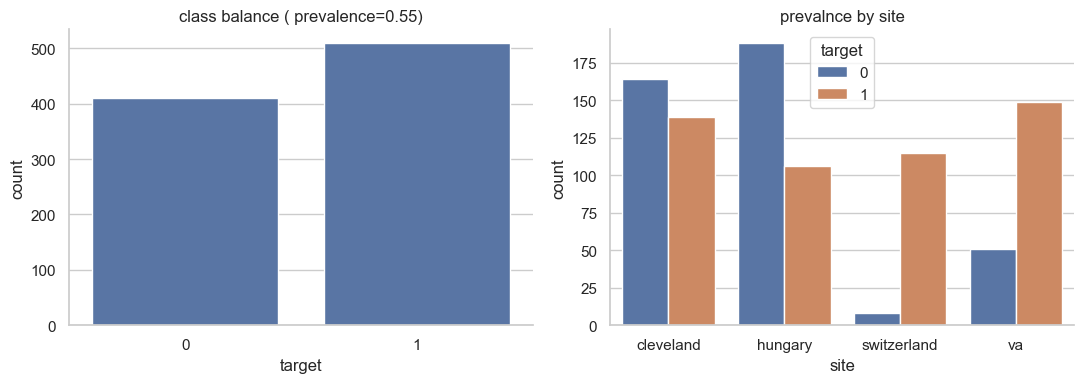

In [10]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
sns.countplot(data=df,x='target',ax=axes[0])
axes[0].set_title(f'class balance ( prevalence={df.target.mean():.2f})')
sns.countplot(df,x='site',hue='target',ax=axes[1])
axes[1].set_title('prevalnce by site')
plt.tight_layout()
sns.despine(top=True,right=True)

In [11]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'site', 'target'], dtype='object')

In [12]:
df=df.drop(columns='exang')
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'oldpeak', 'slope', 'ca', 'thal', 'site', 'target'], dtype='object')

In [13]:
df[df.duplicated(keep=False)]
df=df.drop_duplicates(keep='first')
df.duplicated().sum()
df.shape

(918, 14)

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,918.0,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
sex,918.0,0.789760,0.407701,0.0,1.0,1.0,1.0,1.0
cp,918.0,3.251634,0.931031,1.0,3.0,4.0,4.0,4.0
trestbps,858.0,132.291375,18.532294,80.0,120.0,130.0,140.0,200.0
chol,717.0,246.871688,58.558668,85.0,210.0,240.0,277.0,603.0
fbs,828.0,0.166667,0.372903,0.0,0.0,0.0,0.0,1.0
restecg,916.0,0.604803,0.806354,0.0,0.0,0.0,1.0,2.0
thalach,863.0,137.542294,25.936524,60.0,120.0,140.0,157.0,202.0
oldpeak,856.0,0.880841,1.091673,-2.6,0.0,0.5,1.5,6.2
slope,611.0,1.770867,0.619256,1.0,1.0,2.0,2.0,3.0


<Axes: xlabel='target', ylabel='count'>

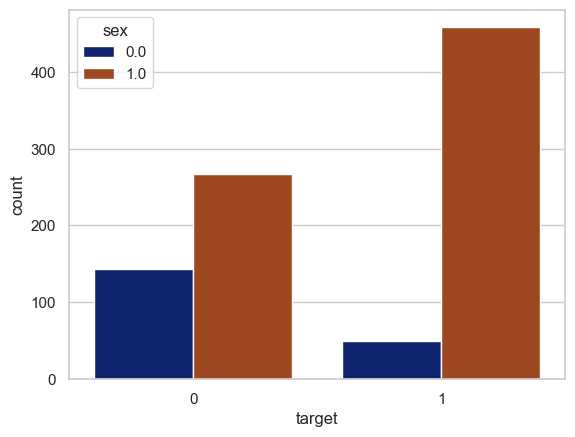

In [15]:
sns.countplot(df,x='target',hue='sex',palette='dark')

In [16]:
df.T.duplicated()

age         False
sex         False
cp          False
trestbps    False
chol        False
fbs         False
restecg     False
thalach     False
oldpeak     False
slope       False
ca          False
thal        False
site        False
target      False
dtype: bool

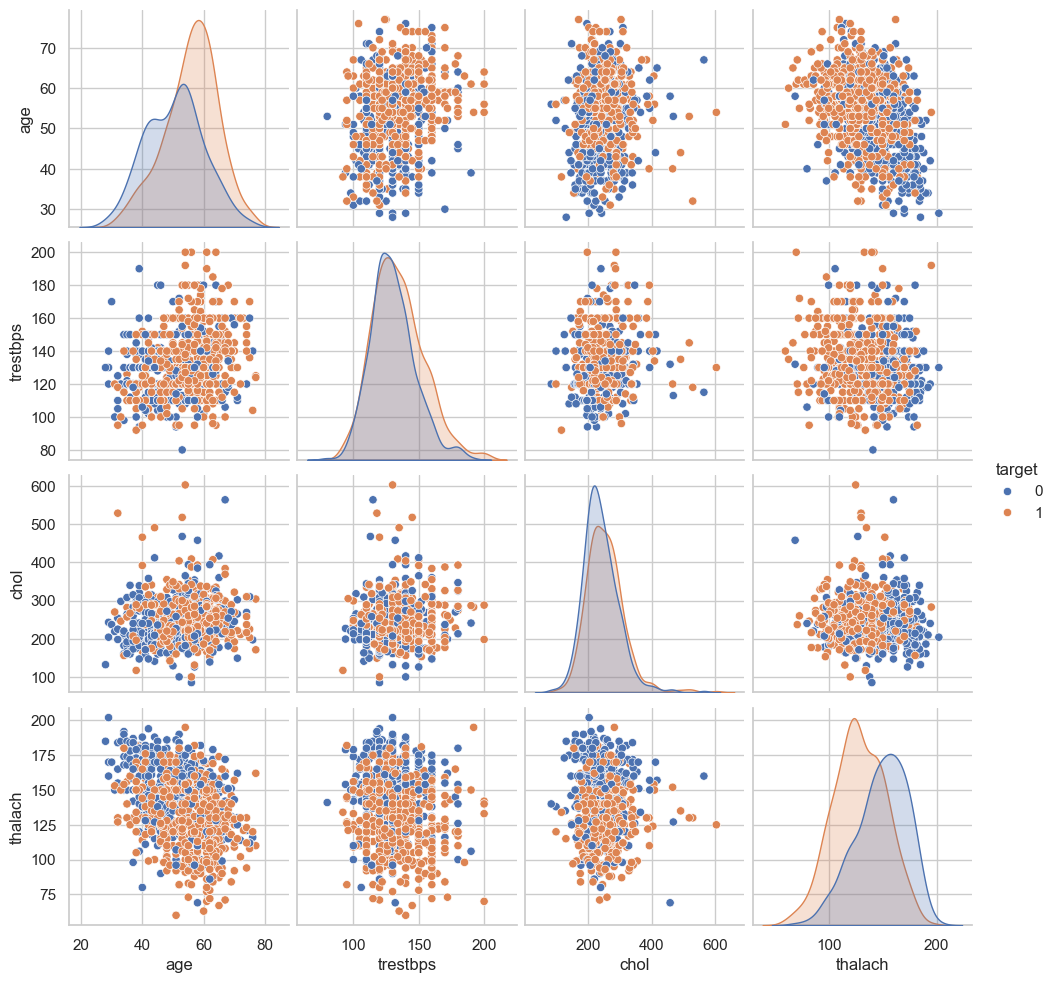

In [17]:
df_pairplot=df[['age','trestbps', 'chol','thalach','target']]
sns.pairplot(df_pairplot,hue='target',kind='scatter')

<Axes: xlabel='age', ylabel='ca'>

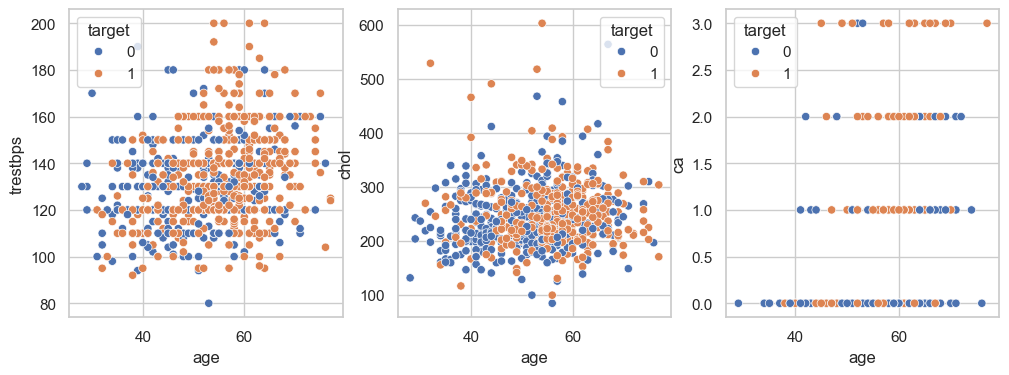

In [18]:
fig,axes=plt.subplots(1,3,figsize=(12,4))
sns.scatterplot(data=df,x='age',y='trestbps',hue='target',ax=axes[0])
sns.scatterplot(data=df,x='age',y='chol',hue='target',ax=axes[1])
sns.scatterplot(data=df,x='age',y='ca',hue='target',ax=axes[2])

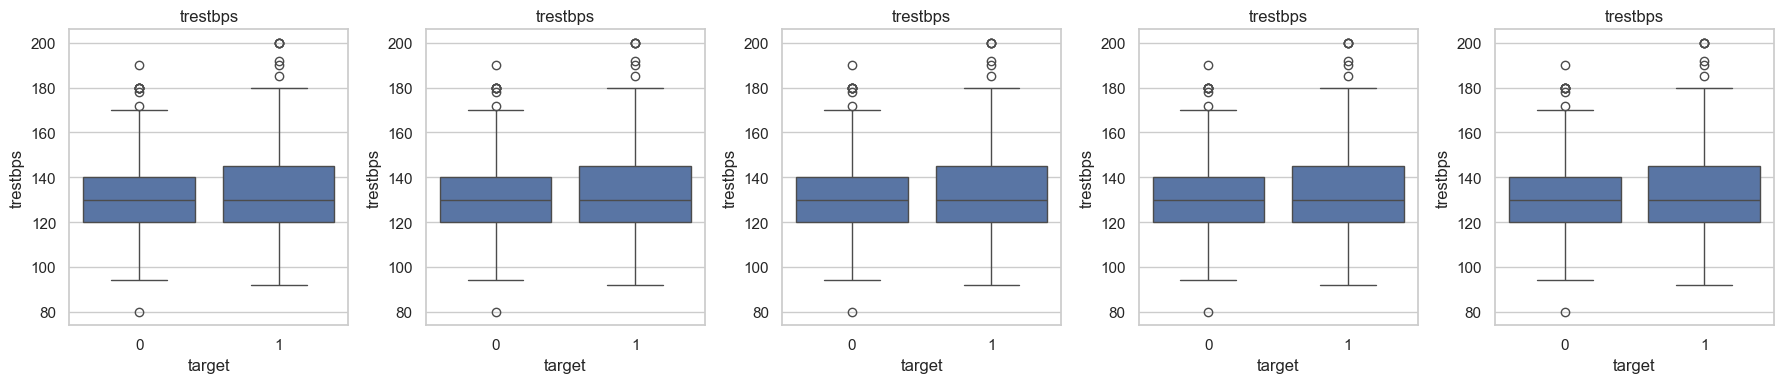

In [19]:
#visual outlier check on cont cols
fig,axes=plt.subplots(1,len(buckets['cont']),figsize=(18,4))
for ax,col in zip(axes,buckets['cont']):
    sns.boxplot(df,x='target',y=c,ax=ax)
    ax.set_title(c)
plt.tight_layout()

Text(0.5, 1.0, 'missingness map (rows grouped by site)')

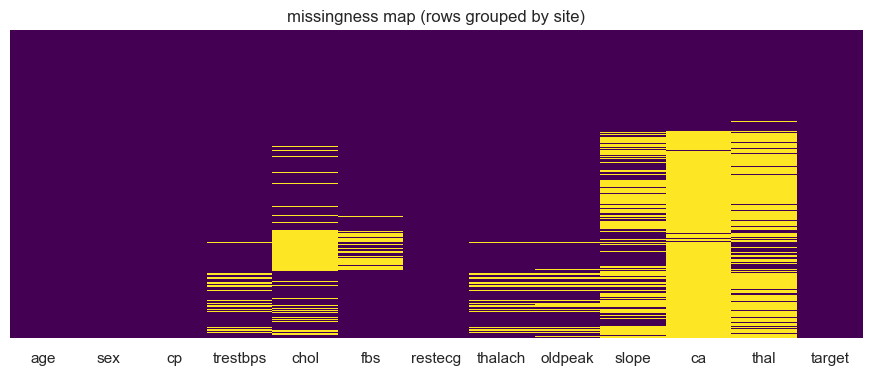

In [20]:
plt.figure(figsize=(11, 4))
sns.heatmap(df.sort_values('site').drop(columns='site').isna(),
            cbar=False, yticklabels=False, cmap='viridis')
plt.title('missingness map (rows grouped by site)')

<Axes: >

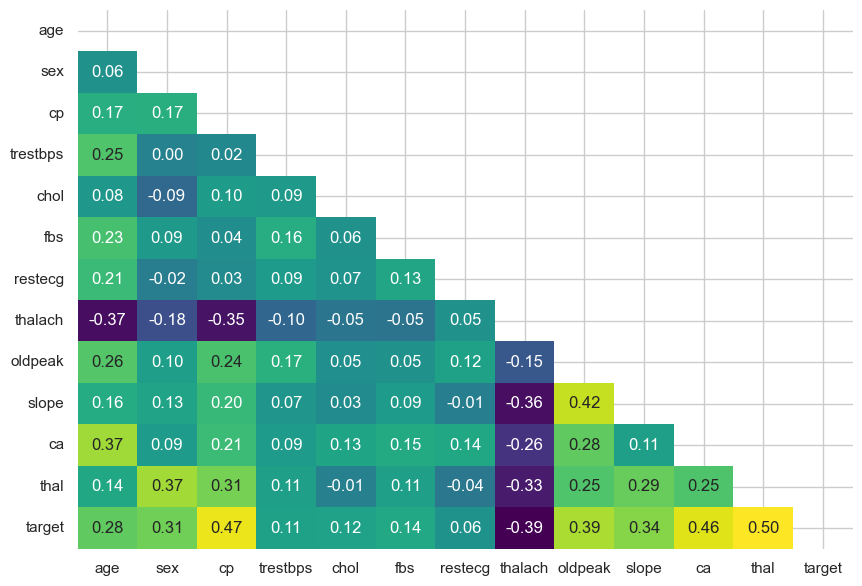

In [21]:
plt.figure(figsize=(10, 7))
corr = df.drop(columns='site').corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='viridis', cbar=False)

we binned by cardinatlity . as cardinality doesnt tell us nominal vs ordinal , cp is nominal . slope is ordinal . restecg codes and ecg value rather than a count
we lose the three strongest single predictors in the Cleveland literature, but every remaining feature is under 10% missing and imputation is a small correction. The model generalises across sites.
can be kept if we want to deploy to only these 4 sites

In [22]:
DROP_HIGH_MISS= True
SITE_AS_FEATURE= False
MISS_THRESHOLD=0.3

ROLES = {
    'cont'   : ['age', 'trestbps', 'chol', 'thalach', 'oldpeak'],
    'binary' : ['sex', 'fbs'],
    'nominal': ['cp', 'restecg', 'thal'],
    'ordinal': ['slope', 'ca'],
}

high_miss= [c for c in sum(ROLES.values(),[]) if df[c].isna().mean()>MISS_THRESHOLD]
print(f'above miss threshold {high_miss}')

if DROP_HIGH_MISS:
    ROLES= {k:[c for c in v if c not in high_miss]for k,v in ROLES.items()}

CONT=ROLES['cont']
BINARY=ROLES['binary']
NUMERIC=CONT + ROLES['ordinal']
NOMINAL=ROLES['nominal'] + (['site']if SITE_AS_FEATURE else [])

FEATURES=NUMERIC+BINARY+NOMINAL

print('numeric :', NUMERIC)
print('binary  :', BINARY)
print('nominal :', NOMINAL)

X=df[FEATURES].copy()
y=df['target'].copy()

groups=df['site'].copy() 
X.shape

above miss threshold ['thal', 'slope', 'ca']
numeric : ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
binary  : ['sex', 'fbs']
nominal : ['cp', 'restecg']


(918, 9)

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE,stratify=y)

g_train=groups.loc[X_train.index]
print(X_train.shape,X_test.shape)
print(f'prevalence  train {y_train.mean()} test {y_test.mean()}')

(688, 9) (230, 9)
prevalence  train 0.5537790697674418 test 0.5521739130434783


In [24]:
#ind audit , if auc of indiacator ~ 0.5 it carrier no label info, safe to add as feature. values ~.65+ means ind is proxy for something outome related
#will inflate cv score

In [25]:
ind_audit=[]
for c in X_train.columns:
    m=X_train[c].isna().astype(int)
    if m.sum() and m.sum() <len(m):
        ind_audit.append({'col': c,
                          'pct_missing': round(m.mean() * 100, 1),
                          'auc_of_indicator': round(roc_auc_score(y_train, m), 3)})
pd.DataFrame(ind_audit).sort_values('auc_of_indicator', ascending=False)


,col,pct_missing,auc_of_indicator
1,chol,21.7,0.604
4,fbs,9.2,0.553
0,trestbps,7.0,0.516
3,oldpeak,7.1,0.514
2,thalach,6.5,0.512


thalach and exang are linearly dependent and come from the same test

In [26]:
from sklearn.impute import MissingIndicator
num_pipeline=Pipeline([('impute',SimpleImputer(strategy='median')),
                       ('scalar',StandardScaler())]) #this ss wrong as indicators would also be scaled
bin_pipeline=Pipeline([
    ('impute',SimpleImputer(strategy='most_frequent'))])
nom_pipeline=Pipeline([
    ('impute',SimpleImputer(strategy='most_frequent')),
    ('ohe',OneHotEncoder(drop='first',handle_unknown='infrequent_if_exist',sparse_output=False))])

preprocessor=ColumnTransformer([('num',num_pipeline,NUMERIC),
                                ('bin',bin_pipeline,BINARY),
                                ('nom',nom_pipeline,NOMINAL),
                                ('missing',MissingIndicator(features='missing-only'),NUMERIC+BINARY)])
preprocessor.fit(X_train)
feature_names= [n for n in preprocessor.get_feature_names_out()]
feature_names,len(feature_names)
preprocessor.get_feature_names_out()

array(['num__age', 'num__trestbps', 'num__chol', 'num__thalach',
       'num__oldpeak', 'bin__sex', 'bin__fbs', 'nom__cp_2.0',
       'nom__cp_3.0', 'nom__cp_4.0', 'nom__restecg_1.0',
       'nom__restecg_2.0', 'missing__missingindicator_trestbps',
       'missing__missingindicator_chol',
       'missing__missingindicator_thalach',
       'missing__missingindicator_oldpeak',
       'missing__missingindicator_fbs'], dtype=object)

In [27]:
Z_train=pd.DataFrame(preprocessor.transform(X_train),columns=feature_names,index=X_train.index)

keep=Z_train.columns[Z_train.std()>1e-8]
dropped=set(Z_train.columns)-set(keep)

if dropped:
    print('dropping zero variance columns',dropped)

Z_train=Z_train[keep]

Zc=sm.add_constant(Z_train,has_constant='add')
vif=pd.DataFrame({'feature':Zc.columns,
                  'VIF':[variance_inflation_factor(Zc.values,i) for i in range(Zc.shape[1])]})
vif[vif.feature != 'const'].sort_values('VIF',ascending=False)
# len(Zc.columns)
# type(Zc)
# Zc.shape

,feature,VIF
15,missing__missingindicator_thalach,18.664161
13,missing__missingindicator_trestbps,16.059066
16,missing__missingindicator_oldpeak,8.404758
10,nom__cp_4.0,5.928315
9,nom__cp_3.0,4.475181
8,nom__cp_2.0,4.255193
14,missing__missingindicator_chol,1.545412
17,missing__missingindicator_fbs,1.443485
4,num__thalach,1.431701
1,num__age,1.418618


In [28]:
r,k=np.linalg.matrix_rank(Zc.values),Zc.shape[1]
assert r==k 

In [29]:
#dummy baselines
def evaluate(y_true, p_hat, threshold=0.5, name=''):
    y_pred = (p_hat >= threshold).astype(int)
    return {'model': name, 'threshold': round(threshold, 3),
            'accuracy' : round(accuracy_score(y_true, y_pred), 3),
            'precision': round(precision_score(y_true, y_pred, zero_division=0), 3),
            'recall'   : round(recall_score(y_true, y_pred, zero_division=0), 3),
            'f1'       : round(f1_score(y_true, y_pred, zero_division=0), 3),
            'roc_auc'  : round(roc_auc_score(y_true, p_hat), 3),
            'avg_prec' : round(average_precision_score(y_true, p_hat), 3),
            'brier'    : round(brier_score_loss(y_true, p_hat), 4)}

rows=[]

for strat in ['most_frequent','stratified','prior']:
    dm=DummyClassifier(strategy=strat,random_state=RANDOM_STATE).fit(X_train,y_train)
    rows.append(evaluate(y_train,dm.predict_proba(X_train)[:,1],name=f'dummy:{strat}'))
pd.DataFrame(rows)

,model,threshold,accuracy,precision,recall,f1,roc_auc,avg_prec,brier
0,dummy:most_frequent,0.5,0.554,0.554,1.000,0.713,0.500,0.554,0.4462
1,dummy:stratified,0.5,0.510,0.558,0.559,0.558,0.504,0.556,0.4898
2,dummy:prior,0.5,0.554,0.554,1.000,0.713,0.500,0.554,0.2471


In [30]:
baseline = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

rows.append(evaluate(y_train, baseline.predict_proba(X_train)[:, 1], name='baseline logit'))
pd.DataFrame(rows)

,model,threshold,accuracy,precision,recall,f1,roc_auc,avg_prec,brier
0,dummy:most_frequent,0.5,0.554,0.554,1.000,0.713,0.500,0.554,0.4462
1,dummy:stratified,0.5,0.510,0.558,0.559,0.558,0.504,0.556,0.4898
2,dummy:prior,0.5,0.554,0.554,1.000,0.713,0.500,0.554,0.2471
3,baseline logit,0.5,0.804,0.815,0.835,0.825,0.881,0.886,0.1362


In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', LogisticRegression(penalty='elasticnet', solver='saga',
                               max_iter=20000, random_state=RANDOM_STATE)),
])
param_grid = {'clf__C'       : np.logspace(-3, 2, 12),
              'clf__l1_ratio': [0.0, 0.25, 0.5, 0.75, 1.0]}

gs = GridSearchCV(pipe, param_grid, scoring='roc_auc', cv=cv,
                  n_jobs=-1, return_train_score=True)
gs.fit(X_train, y_train)

print('best params:', gs.best_params_)
print('best CV auc:', round(gs.best_score_, 4))

best_c=gs.best_params_['clf__C']
best_l1=gs.best_params_['clf__l1_ratio']

best params: {'clf__C': np.float64(0.5336699231206307), 'clf__l1_ratio': 0.5}
best CV auc: 0.8679


In [32]:
final_model =gs.best_estimator_

coef = pd.Series(final_model.named_steps['clf'].coef_[0], index=feature_names)
print(f'non-zero coefficients: {(coef.abs() > 1e-6).sum()} / {len(coef)}')
coef[coef.abs() > 1e-6].sort_values(key=abs, ascending=False).round(3)

non-zero coefficients: 16 / 17


nom__cp_4.0                           1.367
bin__sex                              1.144
missing__missingindicator_fbs         0.841
nom__cp_2.0                          -0.651
missing__missingindicator_chol        0.639
num__oldpeak                          0.637
num__thalach                         -0.481
bin__fbs                              0.301
missing__missingindicator_trestbps    0.241
num__age                              0.238
num__chol                             0.223
nom__restecg_2.0                      0.190
nom__restecg_1.0                      0.117
num__trestbps                         0.103
missing__missingindicator_thalach     0.052
missing__missingindicator_oldpeak     0.026
dtype: float64

In [33]:
from sklearn.model_selection import StratifiedGroupKFold,LeaveOneGroupOut,cross_val_score
logo=LeaveOneGroupOut()
scores=cross_val_score(final_model,X,y,groups=groups,cv=logo,scoring='roc_auc')
print(dict(zip(FILES,scores)))

{'cleveland': np.float64(0.855325495701), 'hungary': np.float64(0.8692866511956413), 'switzerland': np.float64(0.7065217391304348), 'va': np.float64(0.7348966613672496)}


choosing threshold

In [34]:
cv_oof=StratifiedKFold(n_splits=5,shuffle=True,random_state=40)
p_oof = cross_val_predict(final_model, X_train, y_train, cv=cv_oof,
                          method='predict_proba')[:, 1]

prec, rec, thr = precision_recall_curve(y_train, p_oof)
f1s = 2 * prec * rec / (prec + rec + 1e-12)

t_f1 = thr[np.nanargmax(f1s[:-1])]

TARGET_RECALL = 0.90
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
t_recall = thr[ok[np.argmax(prec[:-1][ok])]]

C_FP, C_FN = 1.0, 4.0
t_cost = C_FP / (C_FP + C_FN)

print(f'F1-optimal      t = {t_f1:.3f}')
print(f'recall >= {TARGET_RECALL}  t = {t_recall:.3f}')
print(f'cost-optimal    t = {t_cost:.3f}  (c_FN = {C_FN/C_FP:.0f}x c_FP)')
len(p_oof)


F1-optimal      t = 0.337
recall >= 0.9  t = 0.361
cost-optimal    t = 0.200  (c_FN = 4x c_FP)


688

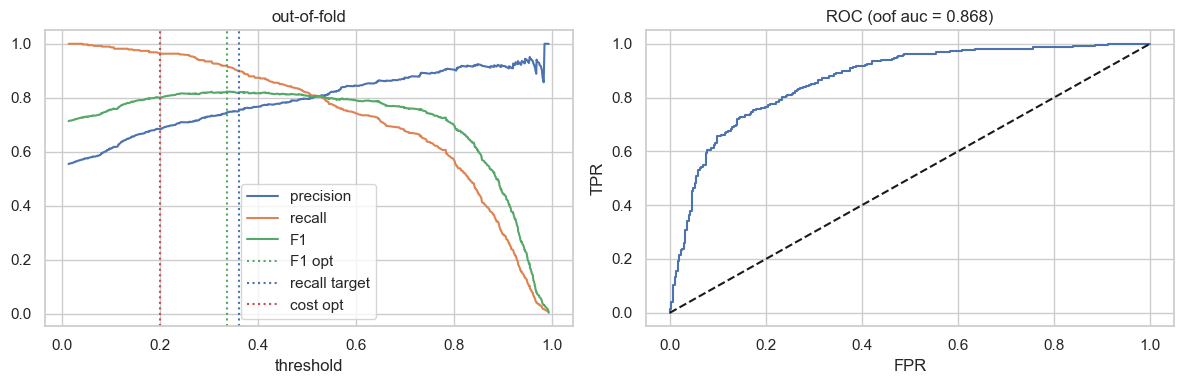

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(thr, prec[:-1], label='precision')
ax[0].plot(thr, rec[:-1],  label='recall')
ax[0].plot(thr, f1s[:-1],  label='F1')
for t, lab, col in [(t_f1, 'F1 opt', 'g'), (t_recall, 'recall target', 'b'),
                    (t_cost, 'cost opt', 'r')]:
    ax[0].axvline(t, ls=':', color=col, label=lab)
ax[0].set_xlabel('threshold'); ax[0].legend(); ax[0].set_title('out-of-fold')

fpr, tpr, _ = roc_curve(y_train, p_oof)
ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR')
ax[1].set_title(f'ROC (oof auc = {roc_auc_score(y_train, p_oof):.3f})')
plt.tight_layout()

In [36]:
THRESHOLD = float(t_cost)    
print('chosen threshold:', round(THRESHOLD, 3))

chosen threshold: 0.2


In [37]:
composite = Z_train[['missing__missingindicator_trestbps',
                      'missing__missingindicator_thalach']].max(axis=1)

Z_train_composite = Z_train.drop(columns=['missing__missingindicator_trestbps',
                                           'missing__missingindicator_thalach'])
Z_train_composite['missing__composite_bp_hr'] = composite

Zc_composite = sm.add_constant(Z_train_composite, has_constant='add')
logit_composite = sm.Logit(y_train, Zc_composite).fit(disp=0)
print(logit_composite.summary2())


                                 Results: Logit
Model:                    Logit                 Method:                MLE       
Dependent Variable:       target                Pseudo R-squared:      0.376     
Date:                     2026-08-13 17:25      AIC:                   624.2622  
No. Observations:         688                   BIC:                   701.3367  
Df Model:                 16                    Log-Likelihood:        -295.13   
Df Residuals:             671                   LL-Null:               -472.90   
Converged:                1.0000                LLR p-value:           7.2567e-66
No. Iterations:           7.0000                Scale:                 1.0000    
---------------------------------------------------------------------------------
                                   Coef.  Std.Err.    z    P>|z|   [0.025  0.975]
---------------------------------------------------------------------------------
const                             -1.7539   0.4786

In [38]:
# #using fitted model 
# drop_cols = ['missing__missingindicator_trestbps', 'missing__missingindicator_thalach']
# Z_train_clean = Z_train.drop(columns=[c for c in drop_cols if c in Z_train.columns])

# Zc_clean = sm.add_constant(Z_train_clean, has_constant='add')
# logit_clean = sm.Logit(y_train, Zc_clean).fit(disp=0)
# print(logit_clean.summary2())


In [39]:
# odds ratios: exp of the coefficients, with CI transformed on the same scale
ci = logit_composite.conf_int()
odds = pd.DataFrame({
    'coef'  : logit_composite.params,
    'OR'    : np.exp(logit_composite.params),
    'OR_lo' : np.exp(ci[0]),
    'OR_hi' : np.exp(ci[1]),
    'p'     : logit_composite.pvalues,
}).drop(index='const').sort_values('OR', ascending=False)
odds.round(3)

,coef,OR,OR_lo,OR_hi,p
nom__cp_4.0,1.448,4.256,1.790,10.117,0.001
bin__sex,1.276,3.584,2.090,6.144,0.000
missing__missingindicator_fbs,1.187,3.276,1.265,8.488,0.015
missing__composite_bp_hr,0.804,2.234,0.165,30.339,0.546
missing__missingindicator_chol,0.664,1.943,1.054,3.581,0.033
num__oldpeak,0.662,1.938,1.522,2.468,0.000
bin__fbs,0.413,1.512,0.826,2.767,0.181
nom__restecg_2.0,0.296,1.344,0.795,2.274,0.270
num__chol,0.241,1.273,1.037,1.562,0.021
num__age,0.225,1.253,0.983,1.596,0.068


In [40]:
# robust (sandwich) SEs — misspecification check, not a heteroscedasticity fix
logit_hc3 = sm.Logit(y_train, Z_train_composite).fit(cov_type='HC3', disp=0)
pd.DataFrame({'se_model': logit_composite.bse, 'se_robust': logit_hc3.bse,
              'ratio': (logit_hc3.bse / logit_composite.bse)}).round(3)

,se_model,se_robust,ratio
bin__fbs,0.309,0.325,1.055
bin__sex,0.275,0.250,0.908
const,0.479,NaN,NaN
missing__composite_bp_hr,1.331,0.791,0.594
missing__missingindicator_chol,0.312,0.297,0.950
missing__missingindicator_fbs,0.486,0.437,0.901
missing__missingindicator_oldpeak,1.338,0.787,0.589
nom__cp_2.0,0.495,0.305,0.616
nom__cp_3.0,0.457,0.287,0.628
nom__cp_4.0,0.442,0.254,0.574


In [41]:
big = pd.DataFrame({'coef': logit_composite.params, 'se': logit_composite.bse})
flag = big[(big.coef.abs() > 8) | (big.se > 8)]
print('separation suspects:' if len(flag) else 'no separation detected')
flag.round(2)

no separation detected


,coef,se


flagged on both: 8 of 688


,age,trestbps,chol,thalach,oldpeak,sex,fbs,cp,restecg
595,58.0,180.0,393.0,110.0,1.0,0.0,0.0,2.0,0.0
384,46.0,150.0,163.0,116.0,0.0,1.0,NaN,3.0,0.0
152,67.0,115.0,564.0,160.0,1.6,0.0,0.0,3.0,2.0
393,48.0,NaN,308.0,NaN,2.0,0.0,0.0,2.0,1.0
858,53.0,155.0,175.0,160.0,NaN,1.0,1.0,3.0,1.0
789,63.0,NaN,217.0,NaN,NaN,1.0,1.0,2.0,1.0
916,62.0,NaN,139.0,NaN,NaN,1.0,0.0,1.0,1.0
743,74.0,NaN,NaN,NaN,NaN,1.0,0.0,3.0,0.0


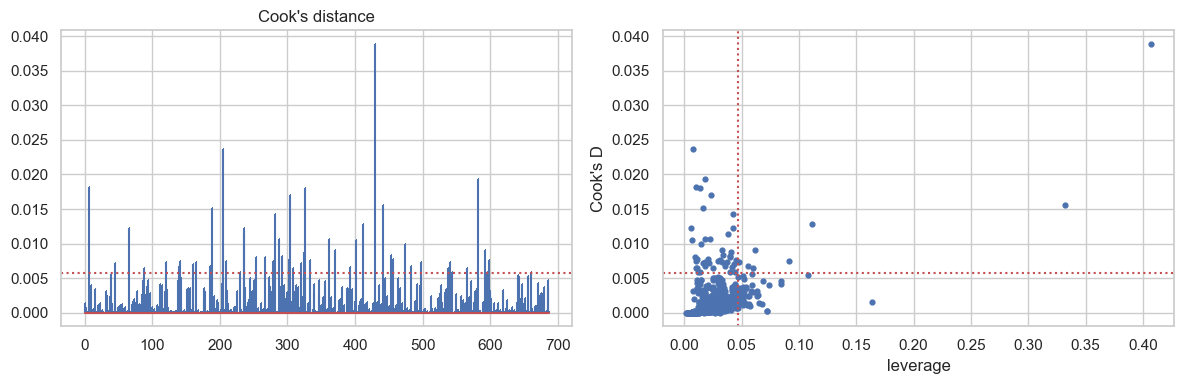

In [42]:
# influence: leverage and Cook's distance via the binomial GLM
glm_fit = sm.GLM(y_train, Z_train_composite, family=sm.families.Binomial()).fit()
infl    = glm_fit.get_influence()
cooks   = infl.cooks_distance[0]
hat     = infl.hat_matrix_diag

n_tr, p_tr = Z_train_composite.shape
cook_cut, hat_cut = 4 / n_tr, 2 * p_tr / n_tr

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].stem(np.arange(n_tr), cooks, markerfmt=',')
ax[0].axhline(cook_cut, color='r', ls=':'); ax[0].set_title("Cook's distance")
ax[1].scatter(hat, cooks, s=12)
ax[1].axvline(hat_cut, color='r', ls=':'); ax[1].axhline(cook_cut, color='r', ls=':')
ax[1].set_xlabel('leverage'); ax[1].set_ylabel("Cook's D")
plt.tight_layout()

flagged = np.where((cooks > cook_cut) & (hat > hat_cut))[0]
print(f'flagged on both: {len(flagged)} of {n_tr}')
X_train.iloc[flagged].head(10)

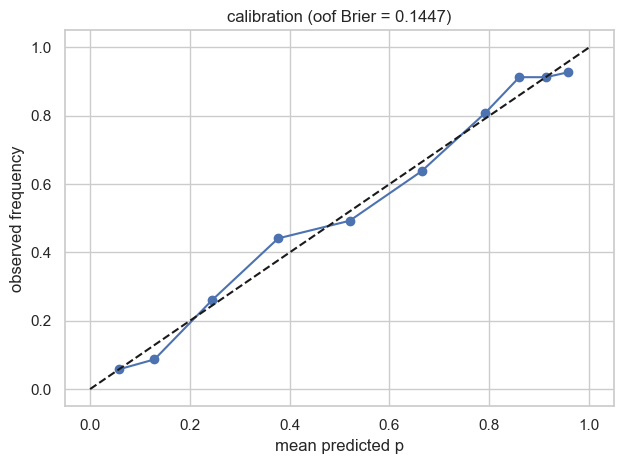

In [43]:
from sklearn.calibration import calibration_curve

frac_pos, mean_pred = calibration_curve(y_train, p_oof, n_bins=10, strategy='quantile')
plt.plot(mean_pred, frac_pos, 'o-')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('mean predicted p'); plt.ylabel('observed frequency')
plt.title(f'calibration (oof Brier = {brier_score_loss(y_train, p_oof):.4f})')
plt.tight_layout()

In [44]:
import shap
print('shap', shap.__version__)

clf = final_model.named_steps['clf']

# use the *unpruned* transformed matrices — these match clf.coef_ column-for-column
Zs_train = pd.DataFrame(preprocessor.transform(X_train),
                        columns=feature_names, index=X_train.index)
Zs_test  = pd.DataFrame(preprocessor.transform(X_test),
                        columns=feature_names, index=X_test.index)

masker    = shap.maskers.Independent(Zs_train, max_samples=1000)
explainer = shap.LinearExplainer(clf, masker)
sv        = explainer(Zs_train)

print('shap values:', sv.values.shape)
print('base value (mean log-odds):', round(float(sv.base_values[0]), 4))

shap 0.52.0
shap values: (688, 17)
base value (mean log-odds): 0.3143


In [45]:
# verify the closed form -- this should be ~0 to machine precision
beta   = clf.coef_[0]
mu     = Zs_train.mean().values
manual = (Zs_train.values - mu) * beta
print('max |phi - beta*(x - mu)|      =', np.abs(sv.values - manual).max())

# verify efficiency on the LOG-ODDS scale
logodds = clf.decision_function(Zs_train)
print('max |sum(phi) + base - logodds| =',
      np.abs(sv.values.sum(1) + sv.base_values - logodds).max())

# and show that it fails on the probability scale
p_hat = final_model.predict_proba(X_train)[:, 1]
i = 0
print(f'\nrow {i}:  sum(phi)+base = {sv.values[i].sum() + sv.base_values[i]:.4f}'
      f'   logit(p) = {np.log(p_hat[i] / (1 - p_hat[i])):.4f}'
      f'   p - p_bar = {p_hat[i] - p_hat.mean():.4f}')

max |phi - beta*(x - mu)|      = 0.0
max |sum(phi) + base - logodds| = 1.7763568394002505e-15

row 0:  sum(phi)+base = -0.8157   logit(p) = -0.8157   p - p_bar = -0.2471


In [46]:
# global importance: mean|SHAP| vs |beta|, and why they differ
imp = pd.DataFrame({
    'beta'         : beta,
    'abs_beta'     : np.abs(beta),
    'spread_E|x-mu|': np.abs(Zs_train.values - mu).mean(0),
    'mean_abs_shap': np.abs(sv.values).mean(0),
}, index=feature_names).sort_values('mean_abs_shap', ascending=False)

rho = imp['abs_beta'].rank().corr(imp['mean_abs_shap'].rank(), method='spearman')
print(f'Spearman(|beta| rank, mean|SHAP| rank) = {rho:.3f}')
imp.round(3)

Spearman(|beta| rank, mean|SHAP| rank) = 0.824


,beta,abs_beta,spread_E|x-mu|,mean_abs_shap
nom__cp_4.0,1.367,1.367,0.498,0.680
num__oldpeak,0.637,0.637,0.808,0.515
num__thalach,-0.481,0.481,0.800,0.385
bin__sex,1.144,1.144,0.333,0.381
missing__missingindicator_chol,0.639,0.639,0.339,0.217
nom__cp_2.0,-0.651,0.651,0.314,0.204
num__age,0.238,0.238,0.808,0.192
num__chol,0.223,0.223,0.675,0.151
missing__missingindicator_fbs,0.841,0.841,0.166,0.140
num__trestbps,0.103,0.103,0.767,0.079


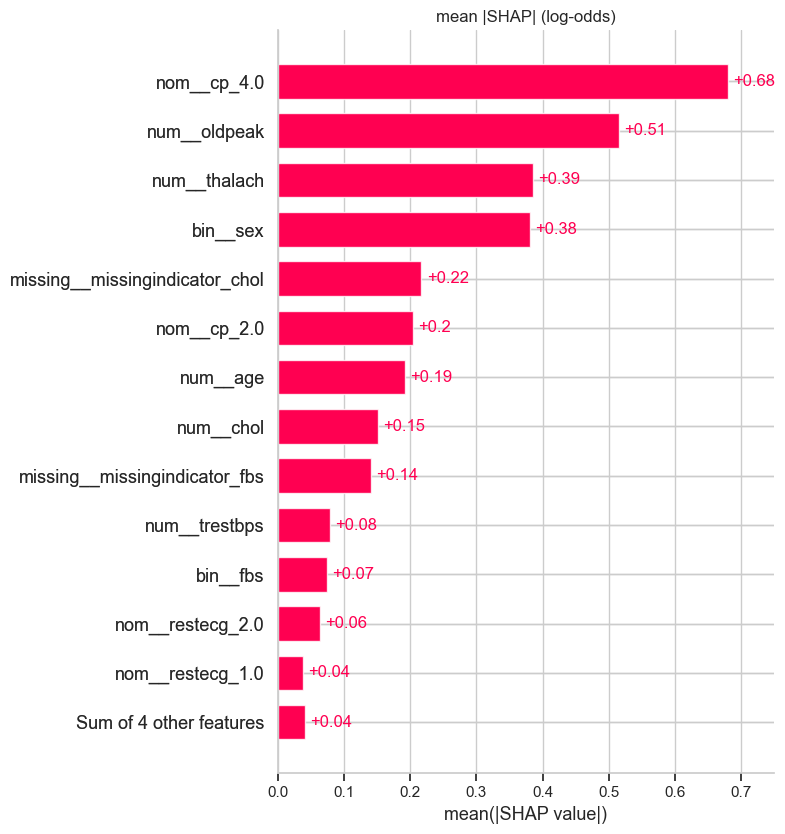

In [47]:
shap.plots.bar(sv, max_display=14, show=False)
plt.title('mean |SHAP| (log-odds)'); plt.tight_layout(); plt.show()

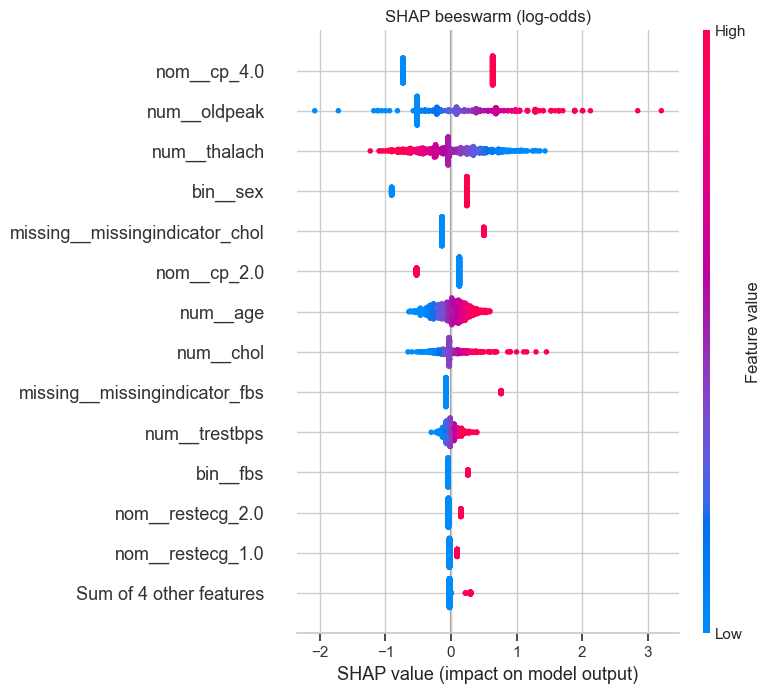

In [48]:
shap.plots.beeswarm(sv, max_display=14, show=False)
plt.title('SHAP beeswarm (log-odds)'); plt.tight_layout(); plt.show()

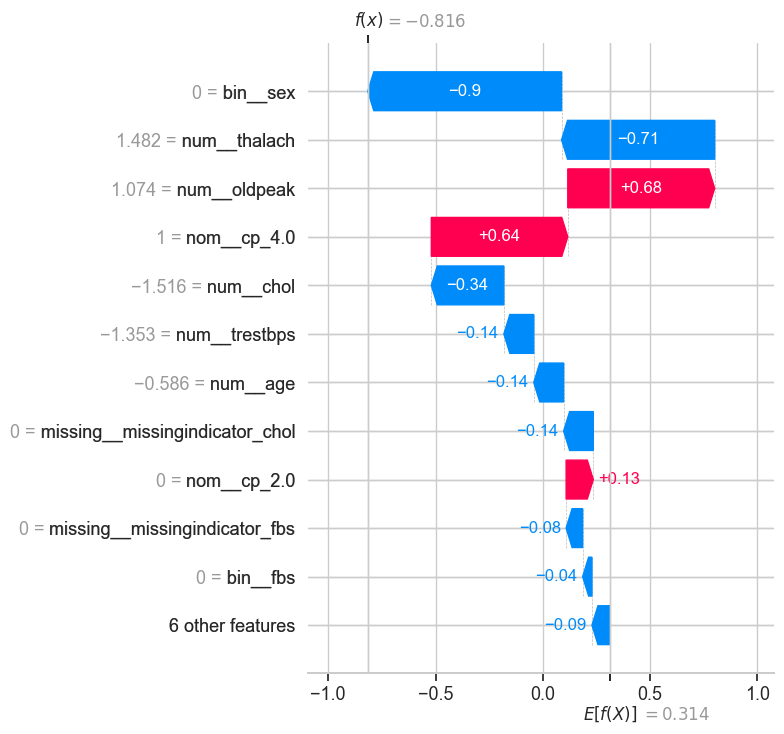

predicted p = 0.307   actual = 0


In [49]:
i = 0
shap.plots.waterfall(sv[i], max_display=12, show=False)
plt.tight_layout(); plt.show()

print(f'predicted p = {p_hat[i]:.3f}   actual = {y_train.iloc[i]}')

In [50]:
# dependence: SHAP value vs the feature's own value -- straight by construction
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(axes, [f for f in ['age', 'thalach', 'oldpeak'] if f in feature_names]):
    a.scatter(Zs_train[c], sv[:, c].values, s=8)
    a.axhline(0, color='k', lw=0.7)
    a.set_xlabel(f'{c} (standardised)'); a.set_ylabel(f'SHAP({c})'); a.set_title(c)
plt.tight_layout()

In [51]:
p_test = final_model.predict_proba(X_test)[:, 1]

rows.append(evaluate(y_test, p_test, threshold=0.5,       name='FInal model '))
rows.append(evaluate(y_test, p_test, threshold=THRESHOLD, name=f'final model @ {THRESHOLD:.2f}'))
pd.DataFrame(rows)

,model,threshold,accuracy,precision,recall,f1,roc_auc,avg_prec,brier
0,dummy:most_frequent,0.5,0.554,0.554,1.000,0.713,0.500,0.554,0.4462
1,dummy:stratified,0.5,0.510,0.558,0.559,0.558,0.504,0.556,0.4898
2,dummy:prior,0.5,0.554,0.554,1.000,0.713,0.500,0.554,0.2471
3,baseline logit,0.5,0.804,0.815,0.835,0.825,0.881,0.886,0.1362
4,FInal model,0.5,0.822,0.807,0.890,0.846,0.913,0.921,0.1184
5,final model @ 0.20,0.2,0.761,0.702,0.984,0.820,0.913,0.921,0.1184


              precision    recall  f1-score   support

           0      0.962     0.485     0.645       103
           1      0.702     0.984     0.820       127

    accuracy                          0.761       230
   macro avg      0.832     0.735     0.732       230
weighted avg      0.818     0.761     0.742       230



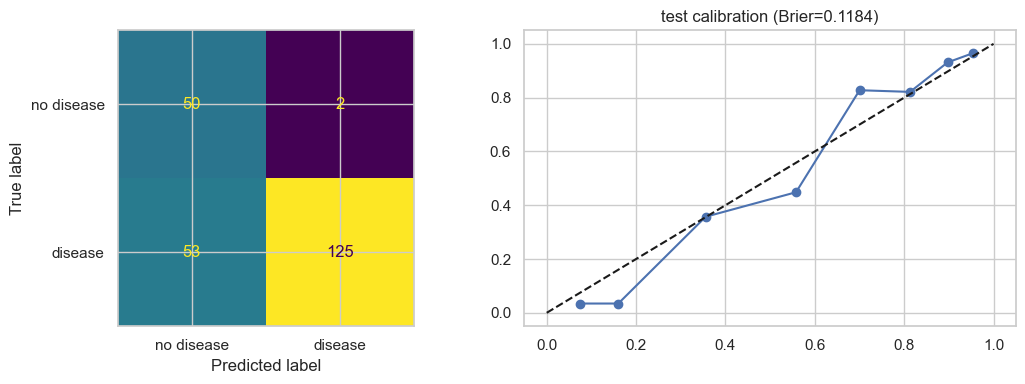

In [53]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

#to be checked

y_pred = (p_test >= THRESHOLD).astype(int)
print(classification_report(y_test, y_pred, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred).T,
                       display_labels=['no disease', 'disease']).plot(ax=ax[0], colorbar=False)

frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=8, strategy='quantile')
ax[1].plot(mean_pred, frac_pos, 'o-'); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set_title(f'test calibration (Brier={brier_score_loss(y_test, p_test):.4f})')
plt.tight_layout()
plt.show()